In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

loading data

In [2]:
# Distances
p_maps = np.load("./data/perturbability_maps.pkl", allow_pickle=True)
p2h_maps = np.load("./data/p2h_maps.pkl", allow_pickle=True)
p2o_maps = np.load("./data/p2o_maps.pkl", allow_pickle=True)

# GEC 
study_results = np.load("./data/study_results.pkl", allow_pickle=True)

# fmri data
fmri = np.load('./data/HCP_early_psychosis_timeseries_cleaned.npz')
flp = fmri['flp']
fhi = fmri['fhi']
ts_ap = fmri['ts_ap']
ts_hc = fmri['ts_hc']
ts_nap = fmri['ts_nap']

# Loading clinical scores data
clinical = np.load('./data/HCP_early_psychosis_clinical_scores.npz')
panss_AP = clinical["panss_AP"]
panss_NAP = clinical["panss_NAP"]
ymrs_AP = clinical["ymrs_AP"]
ymrs_NAP = clinical["ymrs_NAP"]

panns distribution

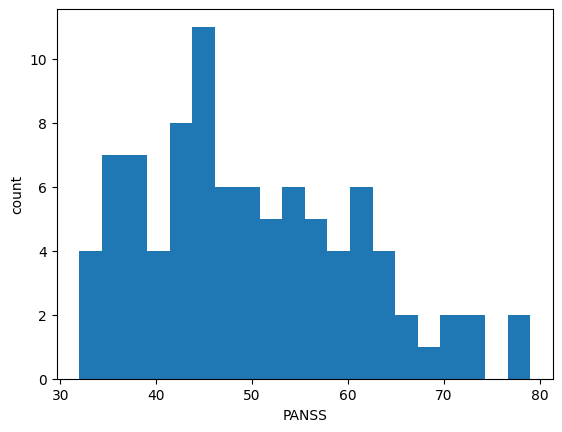

In [33]:
plt.hist(np.concat([panss_NAP, panss_AP]), bins=20)
plt.xlabel("PANSS")
plt.ylabel("count")
plt.show()

features and target

In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb


def get_matrix_features(matrix):
    """
    Helper function to uniformly extract row and column metrics from any 2D matrix.
    """
    # Clean NaNs and zero the diagonal to prevent self-loops from skewing stats
    mat = np.nan_to_num(matrix)
    mat_abs = np.abs(mat)
    np.fill_diagonal(mat_abs, 0)
    
    # Row metrics (Out-degree / Sender properties)
    row_mean = np.mean(mat_abs, axis=1)
    row_std = np.std(mat_abs, axis=1)
    row_max = np.max(mat_abs, axis=1)
    row_median = np.median(mat_abs, axis=1)
    
    # Column metrics (In-degree / Receiver properties)
    col_mean = np.mean(mat_abs, axis=0)
    col_std = np.std(mat_abs, axis=0)
    col_max = np.max(mat_abs, axis=0)
    col_median = np.median(mat_abs, axis=0)
    
    # Network Asymmetry (Out-strength minus In-strength)
    asymmetry = row_mean - col_mean
    
    # Return all 9 metric arrays (each is a 100-element vector)
    return [
        row_mean, row_std, row_max, row_median,
        col_mean, col_std, col_max, col_median, 
        asymmetry
    ]

def extract_subject_features(sub_idx, group, p2h_dict, p2o_dict, study_res, ts_array, tau=1):
    """
    Extracts regional features from 1D maps and uniformly applies row/col 
    metrics to 2D matrices (FC, Ftau, GEC).
    """
    # 1. 1D Perturbability Maps
    p2h_feat = np.abs(p2h_dict[group][sub_idx])
    p2o_feat = np.abs(p2o_dict[group][sub_idx])
    
    sub_ts = ts_array[sub_idx, :, :]
    n_regions = sub_ts.shape[0]

    # 2. Functional Connectivity (FC) Matrix Features
    fc_matrix = np.corrcoef(sub_ts) 
    fc_features = get_matrix_features(fc_matrix)

    # 3. Ftau Matrix Features (Lag-tau Functional Connectivity)
    ts_t0 = sub_ts[:, :-tau]
    ts_ttau = sub_ts[:, tau:]
    
    full_corr = np.corrcoef(ts_t0, ts_ttau)
    ftau_matrix = full_corr[:n_regions, n_regions:]
    ftau_features = get_matrix_features(ftau_matrix)

    # 4. GEC Matrix Features (Effective Connectivity)
    gec_matrix = study_res[group][sub_idx]["GEC_matrix"]
    gec_features = get_matrix_features(gec_matrix)
    
    # 5. Concatenate all derived features
    # Unpacking the feature lists with * injects all 9 arrays per matrix seamlessly
    return np.concatenate([
        # p2h_feat,
        # p2o_feat,
        *fc_features,
        *ftau_features,
        # *gec_features
    ])

# Build the tabular data representation across clinical groups
X_list = []
y_list = []

# Process the Affective Psychosis group
n_subjects_ap = len(p2h_maps['AP'].keys())
for i in range(n_subjects_ap):
    sub_features = extract_subject_features(i, 'AP', p2h_maps, p2o_maps, study_results, ts_ap)
    sub_features = np.append(sub_features, 0) # Append diagnostic marker for AP
    X_list.append(sub_features)
    y_list.append(panss_AP[i])

# Process the Non-Affective Psychosis group
n_subjects_nap = len(p2h_maps['NAP'].keys())
for i in range(n_subjects_nap):
    sub_features = extract_subject_features(i, 'NAP', p2h_maps, p2o_maps, study_results, ts_nap)
    sub_features = np.append(sub_features, 1) # Append diagnostic marker for NAP
    X_list.append(sub_features)
    y_list.append(panss_NAP[i])

X = np.array(X_list)
y = np.array(y_list)

# Strip out rows where clinical outcomes are missing
valid_mask = ~np.isnan(y)
X = X[valid_mask]
y = y[valid_mask]


Regressor

In [4]:
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import xgboost as xgb
import numpy as np

# Initialize lists to store true and predicted values across LOOCV iterations
y_true_all = []
y_pred_all = []

# Setup Leave-One-Out Cross-Validation iterator
loo = LeaveOneOut()

for train_index, test_index in loo.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    
    # Instantiate a regularized tree architecture to manage wide feature spaces
    xgb_model = xgb.XGBRegressor(
        n_estimators=180,
        max_depth=3,
        learning_rate=0.04,
        subsample=0.8,
        colsample_bytree=0.3,
        reg_alpha=0.8,
        reg_lambda=1.5,
        random_state=42
    )
    
    # Train on the N-1 subjects
    xgb_model.fit(X_train, y_train)
    
    # Predict on the single isolated subject
    pred = xgb_model.predict(X_test)
    
    # Record metrics for final cross-validation aggregation
    y_true_all.append(y_test[0])
    y_pred_all.append(pred[0])

# Convert collected evaluations back to numpy arrays
y_true_all = np.array(y_true_all)
y_pred_all = np.array(y_pred_all)

# Output final metrics aggregated over all LOOCV iterations
print(f"LOOCV RMSE: {np.sqrt(mean_squared_error(y_true_all, y_pred_all)):.4f}")
print(f"LOOCV MAE: {mean_absolute_error(y_true_all, y_pred_all):.4f}")
print(f"LOOCV R² Score: {r2_score(y_true_all, y_pred_all):.4f}")

LOOCV RMSE: 12.5867
LOOCV MAE: 10.4786
LOOCV R² Score: -0.2670


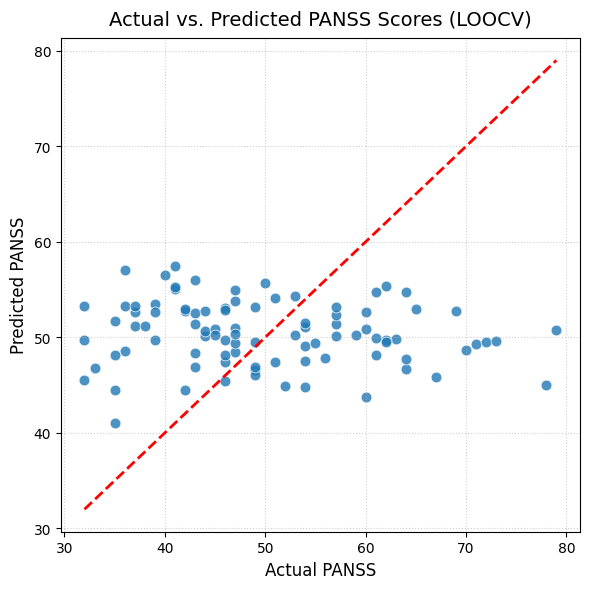

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure space for a single plot
plt.figure(figsize=(6, 6))

# Plot Actual vs Predicted scores using the aggregated LOOCV arrays
sns.scatterplot(x=y_true_all, y=y_pred_all, color='#1f77b4', s=60, alpha=0.8)

# Add the identity line representing perfect predictions
min_val = min(min(y_true_all), min(y_pred_all))
max_val = max(max(y_true_all), max(y_pred_all))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)

# Format the plot aesthetics
plt.title('Actual vs. Predicted PANSS Scores (LOOCV)', fontsize=14, pad=10)
plt.xlabel('Actual PANSS', fontsize=12)
plt.ylabel('Predicted PANSS', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Categorical

In [ ]:
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_sample_weight
from imblearn.over_sampling import RandomOverSampler
import xgboost as xgb
import pandas as pd
import numpy as np

# Apply your manual clinical thresholds
y_categorical = pd.cut(
    y, 
    bins=[-np.inf, 40, 60, np.inf], 
    labels=[0, 1, 2]
).astype(int)

print(
np.unique(y_categorical, return_counts=True)
)

y_true_all = []
y_pred_all = []

loo = LeaveOneOut()

# Initialize the oversampler
ros = RandomOverSampler(random_state=42)

for train_index, test_index in loo.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y_categorical[train_index], y_categorical[test_index]
    
    # 1. Oversample the training split to create equal class distributions
    X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)
    
    # 2. Compute dynamic sample weights on the resampled data
    # (Acts as a safety net if you ever use partial oversampling)
    weights = compute_sample_weight(class_weight='balanced', y=y_train_resampled)
    
    # Configure the regularized model architecture
    xgb_model = xgb.XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.04,
        subsample=0.8,
        colsample_bytree=0.3,
        reg_alpha=0.8,
        reg_lambda=1.5,
        eval_metric='mlogloss',
        random_state=42
    )
    
    # Train the model with BOTH resampled data and explicit sample weights
    xgb_model.fit(X_train_resampled, y_train_resampled, sample_weight=weights)
    
    # Predict on the strictly unseen test subject
    pred = xgb_model.predict(X_test)
    
    y_true_all.append(y_test[0])
    y_pred_all.append(pred[0])

# Re-convert collected evaluations to arrays
y_true_all = np.array(y_true_all)
y_pred_all = np.array(y_pred_all)

# Aggregate LOOCV metric evaluation
print(f"LOOCV Total Accuracy: {accuracy_score(y_true_all, y_pred_all):.4f}\n")
print("Classification Report:")
print(classification_report(
    y_true_all, 
    y_pred_all, 
    labels=[0, 1, 2], 
    target_names=['Low', 'Mid', 'High']
))
print("Confusion Matrix:")
print(confusion_matrix(y_true_all, y_pred_all, labels=[0, 1, 2]))

LOOCV Total Accuracy: 0.5217

Classification Report:
              precision    recall  f1-score   support

         Low       0.36      0.26      0.30        19
         Mid       0.58      0.78      0.67        54
        High       0.17      0.05      0.08        19

    accuracy                           0.52        92
   macro avg       0.37      0.36      0.35        92
weighted avg       0.45      0.52      0.47        92

Confusion Matrix:
[[ 5 14  0]
 [ 7 42  5]
 [ 2 16  1]]
